# Agente inversor: el algoritmo de aprendizaje

Este notebook documenta el algoritmo con el que se entrenan los agentes de
`investor_reward.ipynb`: qué es, con qué hiperparámetros y por qué. Los
valores no se copian a mano: se leen de los modelos guardados, así que la
tabla corresponde exactamente a lo que se entrenó.

Necesita los modelos de `saves/` (los crea `investor_reward.ipynb`).

In [1]:
import os
from pathlib import Path

# Ejecutar desde la raíz del repositorio, como la CLI.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import stable_baselines3
import torch
from stable_baselines3 import DQN

from rl_games_sb import config, envs, investor, registry

cfg = config.load("configs/investor_dqn_penalized.yaml")
SEEDS = [0, 1, 2]
models = {s: DQN.load(f"saves/dqn_investor-pen400_seed{s}.zip", device="cpu") for s in SEEDS}
model = models[0]
env = envs.make(cfg.env)

print(f"Stable-Baselines3 {stable_baselines3.__version__}, PyTorch {torch.__version__}")
print(f"Entorno: {cfg.env} | observación {env.observation_space.shape} | acciones {env.action_space}")

Stable-Baselines3 2.9.0, PyTorch 2.14.1+cu130
Entorno: investor-penalized-v0 | observación (6,) | acciones Discrete(3)


## 1. Algoritmo: DQN

**Deep Q-Network** (Mnih et al., 2015), en la implementación de
Stable-Baselines3. Una red neuronal estima, para cada estado $s$, el valor
$Q(s, a)$ de cada acción: el retorno descontado que se espera obtener si hoy
se elige la exposición $a$ y después se sigue la mejor política. El agente
elige la acción con mayor $Q$.

La red se entrena para cumplir la ecuación de Bellman, minimizando (con
pérdida de Huber) la diferencia entre $Q(s_t, a_t)$ y el objetivo

$$y_t = r_t + \gamma \max_{a'} Q_{\text{target}}(s_{t+1}, a'),$$

donde $Q_{\text{target}}$ es una copia de la red que se actualiza cada cierto
número de pasos, para que el objetivo no se mueva en cada actualización.

**Por qué DQN y no PPO:**

- **Acciones discretas.** Las acciones son 3 exposiciones (0 %, 50 %, 100 %),
  justo el caso para el que se diseñó DQN: una salida por acción y se elige
  la mayor. PPO también sirve, pero aprende una distribución de probabilidad
  sobre las acciones, algo innecesario aquí.
- **Pocos datos.** Train tiene solo 1.363 días. DQN es *off-policy*: guarda
  cada transición en un *replay buffer* y la reutiliza en muchas
  actualizaciones. PPO es *on-policy*: usa cada lote de experiencia unas pocas
  veces y lo descarta.
- **Interpretable.** Los valores Q dicen cuánto prefiere el agente cada nivel
  de exposición en cada día (sección 5).

## 2. Arquitectura de la red

In [2]:
print(model.q_net)
n_params = sum(p.numel() for p in model.q_net.parameters())
print(f"\nParámetros entrenables: {n_params:,}")

QNetwork(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (q_net): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)

Parámetros entrenables: 4,803


Un perceptrón multicapa pequeño:

```
6 entradas  ──►  64 (ReLU)  ──►  64 (ReLU)  ──►  3 salidas
(5 indicadores                                   Q(s, 0 %), Q(s, 50 %), Q(s, 100 %)
 + posición)
```

- **Entrada:** el estado del entorno, es decir, los 5 indicadores normalizados
  más la posición actual. No hace falta una red convolucional ni recurrente,
  porque el estado es un vector corto que ya resume el pasado reciente.
- **Tamaño:** 4.803 parámetros, mucho menos que la red de 256×256 que usa el
  repositorio para LunarLander. Con solo 1.363 días de entrenamiento, una red
  grande tiene aún más capacidad para memorizar el camino de precios, el
  problema que encontramos en la parte 9. No se ajustó el tamaño: es un valor
  razonable que conviene revisar si se ajustan hiperparámetros.
- **Red objetivo:** una segunda copia idéntica, $Q_{\text{target}}$, que
  calcula el objetivo de Bellman.

## 3. Hiperparámetros

In [3]:
updates = (model.num_timesteps - model.learning_starts) // model.train_freq.frequency * model.gradient_steps
values = {
    "algoritmo": "DQN (Stable-Baselines3)",
    "política": type(model.policy).__name__ + " (MLP)",
    "capas ocultas": str(cfg.hyperparams["policy_kwargs"]["net_arch"]),
    "learning rate": model.learning_rate,
    "optimizador": f"{type(model.policy.optimizer).__name__}",
    "función de pérdida": "Huber (smooth L1)",
    "recorte del gradiente (norma máx.)": model.max_grad_norm,
    "batch size": model.batch_size,
    "factor de descuento γ": model.gamma,
    "pasos de entrenamiento": f"{model.num_timesteps:,}",
    "episodios": model._episode_num,
    "días por episodio": len(investor.InvestorEnv(period="train").dates) - 1,
    "actualizaciones de la red": f"{updates:,}",
    "replay buffer (transiciones)": f"{model.buffer_size:,}",
    "pasos aleatorios antes de aprender": f"{model.learning_starts:,}",
    "una actualización cada (pasos)": model.train_freq.frequency,
    "red objetivo: se copia cada (pasos)": model.target_update_interval,
    "exploración": "ε-greedy, ε lineal y luego constante",
    "ε inicial": model.exploration_initial_eps,
    "ε final": model.exploration_final_eps,
    "fracción de pasos para bajar ε": model.exploration_fraction,
    "semillas": ", ".join(str(m.seed) for m in models.values()),
    "dispositivo": str(model.device),
}
pd.Series(values, name="valor").to_frame()

,valor
algoritmo,DQN (Stable-Baselines3)
política,DQNPolicy (MLP)
capas ocultas,"[64, 64]"
learning rate,0.0001
optimizador,Adam
función de pérdida,Huber (smooth L1)
recorte del gradiente (norma máx.),10
batch size,64
factor de descuento γ,0.99
pasos de entrenamiento,"300,000"


| Hiperparámetro | Valor | Por qué |
|---|---|---|
| Learning rate | 1e-4 | Valor estándar de DQN (RL Zoo lo usa en Atari). Las recompensas son pequeñas (~0,01 al día), así que no conviene un paso grande que haga oscilar las estimaciones de Q. |
| Batch size | 64 | Cada actualización promedia 64 transiciones del buffer: suficiente para reducir el ruido de un retorno diario muy variable, sin que cada paso sea costoso. |
| γ | 0,99 | Horizonte efectivo de $1/(1-\gamma)$ = 100 días hábiles (~5 meses). Clave con la penalización de v1: cambiar de posición cuesta 4 % de recompensa de inmediato, y solo vale la pena si el agente valora la ganancia de las semanas siguientes. Con γ = 0,9 (10 días) casi ningún cambio compensaría. |
| Pasos | 300.000 | 220 pasadas por los 1.363 días de train. Las curvas de la parte 9 muestran que v1 se estabiliza en validación desde ~30.000 pasos, así que el presupuesto alcanza de sobra. |
| Replay buffer | 100.000 | Guarda las últimas ~73 pasadas por train. Como el camino de precios siempre es el mismo, el buffer cubre todos los días muchas veces, con distintas posiciones y acciones. |
| Pasos aleatorios iniciales | 5.000 | ~3,7 episodios con acciones al azar para llenar el buffer antes de la primera actualización. |
| Una actualización cada 4 pasos | 4 | La proporción clásica de DQN: unas 74.000 actualizaciones en total. |
| Red objetivo | copia cada 1.000 pasos | Mantiene fijo el objetivo de Bellman durante ~250 actualizaciones, lo que estabiliza el aprendizaje. |
| ε inicial / final | 1,0 / 0,02 | Empieza explorando al azar y termina eligiendo la mejor acción el 98 % de las veces. |
| Fracción para bajar ε | 0,3 | ε baja durante los primeros 90.000 pasos (~66 episodios) y después queda en 0,02. |

## 4. Estrategia de exploración

**ε-greedy:** en cada paso, con probabilidad ε el agente elige una acción al
azar, y con probabilidad 1 − ε elige la de mayor Q. ε baja linealmente de 1,0
a 0,02 en el primer 30 % del entrenamiento y después queda fijo.

En este entorno explorar cuesta: una acción al azar suele cambiar la
posición, y paga el costo real y la penalización. Por eso conviene que ε
termine bajo (0,02). Al evaluar, siempre se usa la política *greedy* (ε = 0).

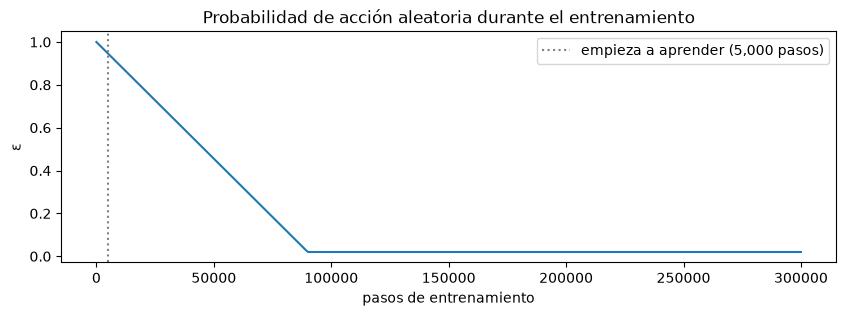

In [4]:
steps = np.linspace(0, model.num_timesteps, 500)
eps = [model.exploration_schedule(1 - s / model.num_timesteps) for s in steps]

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(steps, eps)
ax.axvline(model.learning_starts, color="gray", ls=":", label=f"empieza a aprender ({model.learning_starts:,} pasos)")
ax.set_xlabel("pasos de entrenamiento")
ax.set_ylabel("ε")
ax.set_title("Probabilidad de acción aleatoria durante el entrenamiento")
ax.legend()
plt.show()

## 5. Qué aprendió: los valores Q en validación

Para cada día de 2015, la red da tres valores, uno por exposición. Abajo se
grafica la ventaja de cada exposición frente a estar en efectivo,
$Q(s, a) - Q(s, 0\,\%)$, con la posición que traía el agente ese día.
Cuando las curvas están por debajo de cero, el agente prefiere el efectivo.

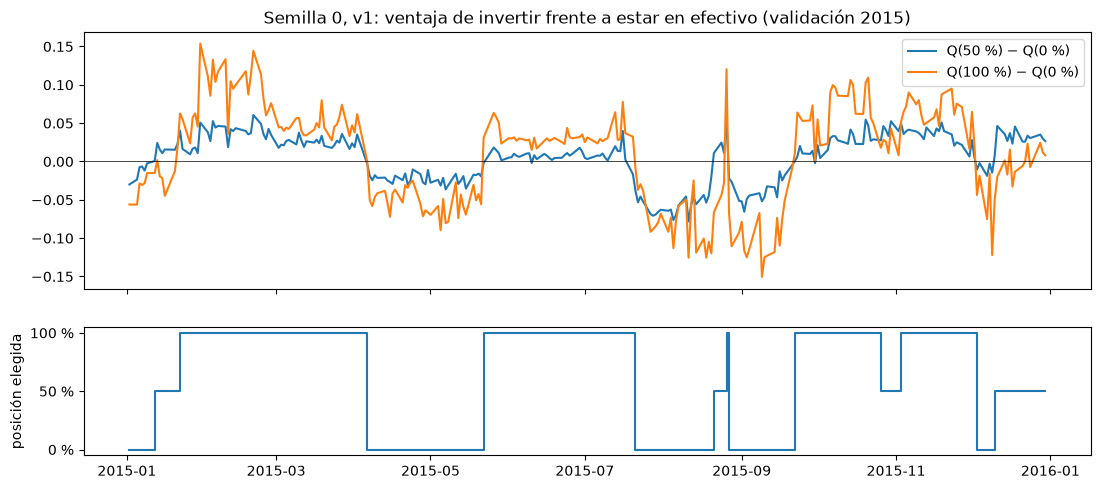

In [5]:
# El agente greedy: en cada día, la acción con mayor Q (lo mismo que model.predict).
valid_env = investor.InvestorEnv(period="valid")
obs, info = valid_env.reset()
rows, done = [], False
while not done:
    with torch.no_grad():
        values = model.q_net(torch.as_tensor(obs).unsqueeze(0)).numpy()[0]
    action = int(values.argmax())
    rows.append({"date": info["date"], **dict(zip(["0 %", "50 %", "100 %"], values)),
                 "position": investor.POSITIONS[action]})
    obs, _, terminated, truncated, info = valid_env.step(action)
    done = terminated or truncated
q = pd.DataFrame(rows).set_index("date")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True, height_ratios=[2, 1])
ax1.plot(q["50 %"] - q["0 %"], label="Q(50 %) − Q(0 %)")
ax1.plot(q["100 %"] - q["0 %"], label="Q(100 %) − Q(0 %)")
ax1.axhline(0, color="black", lw=0.5)
ax1.set_title("Semilla 0, v1: ventaja de invertir frente a estar en efectivo (validación 2015)")
ax1.legend()
ax2.step(q.index, q["position"], where="post")
ax2.set_yticks([0, 0.5, 1], ["0 %", "50 %", "100 %"])
ax2.set_ylabel("posición elegida")
plt.show()

**Cómo leerlo:**

- **Regímenes.** La ventaja de invertir es positiva durante semanas
  (febrero–marzo, junio–julio, octubre–noviembre) y negativa en otras
  (abril–mayo, agosto–septiembre). El agente cambia de posición cuando esa
  ventaja cambia de signo: no reacciona día a día, sino a cambios de régimen
  que duran.
- **El costo de cambiar está en Q.** La posición actual es parte del estado.
  Justo después de un cambio (por ejemplo, la salida a efectivo a comienzos de
  abril), la curva se aleja de cero, porque volver atrás costaría otra vez la
  penalización (hasta 0,04 de recompensa). Por eso el agente no se pasa de un
  lado a otro ante cada pequeña variación.
- **Leer el signo más que la magnitud.** Una diferencia de 0,1 equivaldría a
  esperar ~10 % más de crecimiento en los próximos meses, demasiado para una
  señal tan débil como la que encontró el análisis exploratorio. DQN tiende a
  sobreestimar los valores Q (al tomar el máximo de estimaciones con ruido), así
  que lo informativo es qué acción prefiere, no por cuánto.

## 6. Criterio de parada

**Presupuesto fijo de 300.000 pasos (220 episodios), sin parada temprana.**

- La parada temprana con validación (quedarse con el punto del entrenamiento
  que mejor resultado da en 2015) sería una segunda selección sobre el mismo
  año, después de haber elegido κ con él, y haría todavía más optimista el
  resultado de validación.
- Las curvas de aprendizaje de la parte 9 muestran que no hace falta: con v1,
  el retorno en validación se mantiene en una banda estable (~+40 % a +70 %)
  desde los primeros 30.000 pasos, así que el punto exacto donde se detiene no
  cambia la conclusión. Con v0 ningún punto de parada habría servido, porque
  la validación nunca mejora.
- Durante el entrenamiento se evalúa cada 30.000 pasos en train y validación
  solo para **observar** (esas curvas), no para elegir el modelo.

## 7. Semillas aleatorias y reproducibilidad

Cada configuración se entrena con 3 semillas: 0, 1 y 2. El entorno es
determinista (los precios son siempre los mismos), así que la semilla
controla todo lo aleatorio del entrenamiento: los pesos iniciales de la red,
las acciones al azar de la exploración y las transiciones que se toman del
buffer en cada actualización.

`seed` de Stable-Baselines3 fija las semillas de Python, NumPy y PyTorch. En
CPU el entrenamiento es **reproducible bit a bit**: la misma semilla da
exactamente la misma red. Se comprueba con dos entrenamientos cortos.

In [6]:
def short_run(seed, steps=6_000):
    m = registry.create(cfg.algo, cfg.env, seed=seed, **cfg.hyperparams | {"learning_starts": 1_000})
    m.learn(steps)
    return torch.cat([p.flatten() for p in m.q_net.parameters()])


a, b, c = short_run(0), short_run(0), short_run(1)
print("Misma semilla (0 y 0), pesos idénticos:", torch.equal(a, b))
print("Distinta semilla (0 y 1), pesos idénticos:", torch.equal(a, c))

Misma semilla (0 y 0), pesos idénticos: True
Distinta semilla (0 y 1), pesos idénticos: False


**Por qué 3 semillas y no una:** en la parte 9, con la misma recompensa y los
mismos hiperparámetros, el retorno de v0 en validación fue −3 %, +21 % o +4 %
según la semilla. Una sola corrida puede llevar a conclusiones opuestas, así
que todos los resultados se reportan con su media y su peor semilla.

En GPU el entrenamiento no es reproducible bit a bit (algunas operaciones de
CUDA no son deterministas). Por eso, y porque una red de 4.803 parámetros es
más rápida en CPU, se entrena en CPU.